Cell 1 — Install dependencies

In [1]:
!pip install matminer pymatgen scikit-learn --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.8/825.8 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.8/354.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 979.1/979.1 kB 20.8 MB/s eta 0:00:00
   ━━━━━━

Cell 2 — Load the cubic baseline data

In [2]:
!git clone https://github.com/Yuxinya/SG_predict.git

import pandas as pd
df = pd.read_csv('SG_predict/ML/cubic.csv')
print('Shape:', df.shape)
df.head()

Cloning into 'SG_predict'...
remote: Enumerating objects: 137, done.
remote: Total 137 (delta 0), reused 0 (delta 0), pack-reused 137 (from 1)
Receiving objects: 100% (137/137), 29.94 MiB | 25.55 MiB/s, done.
Resolving deltas: 100% (60/60), done.
Shape: (17367, 261)


,mp-id,space_group,formula,full_formula,composition,minimum Number,maximum Number,range Number,mean Number,avg_dev Number,...,Md,No,Lr,NComp,total atom number,maximum atom number,minimum atom number,average atom number,specific value,atom number variance
0,mp-41734,195,Na8Al6Si6SO28,Na8Al6Si6S1O28,Na8 Al6 Si6 S1 O28,8,16,8,10.000000,2.285714,...,0,0,0,5,49,28,1,9.800000,1.0,0.036718
1,mp-1220843,195,Na8Al6Si6BrClO24,Na8Al6Si6Br1Cl1O24,Na8 Al6 Si6 Br1 Cl1 O24,8,35,27,10.739130,2.858223,...,0,0,0,6,46,24,1,7.666667,1.0,0.028460
2,mp-1220856,195,Na8Al6Si6IClO24,Na8Al6Si6I1Cl1O24,Na8 Al6 Si6 I1 Cl1 O24,8,53,45,11.130435,3.311909,...,0,0,0,6,46,24,1,7.666667,1.0,0.028460
3,mp-759730,195,Fe(Bi5O8)5,Fe1Bi25O40,Fe1 Bi25 O40,8,83,75,36.681818,35.089532,...,0,0,0,3,66,40,1,22.000000,1.0,0.059229
4,mp-757873,195,Co(Bi5O8)5,Co1Bi25O40,Co1 Bi25 O40,8,83,75,36.696970,35.078053,...,0,0,0,3,66,40,1,22.000000,1.0,0.059229


Cell 3 — Class distribution

space_group
195       5
196       2
197      44
198     381
199      49
200      84
201      54
202      28
203      68
204     285
205     289
206     123
208       3
209       2
210       2
212      69
213      60
214      50
215     147
216    1415
217     203
218      97
219      22
220     205
221    3059
222       2
223     279
224      49
225    8449
226      55
227    1215
228      10
229     234
230     328
Name: count, dtype: int64


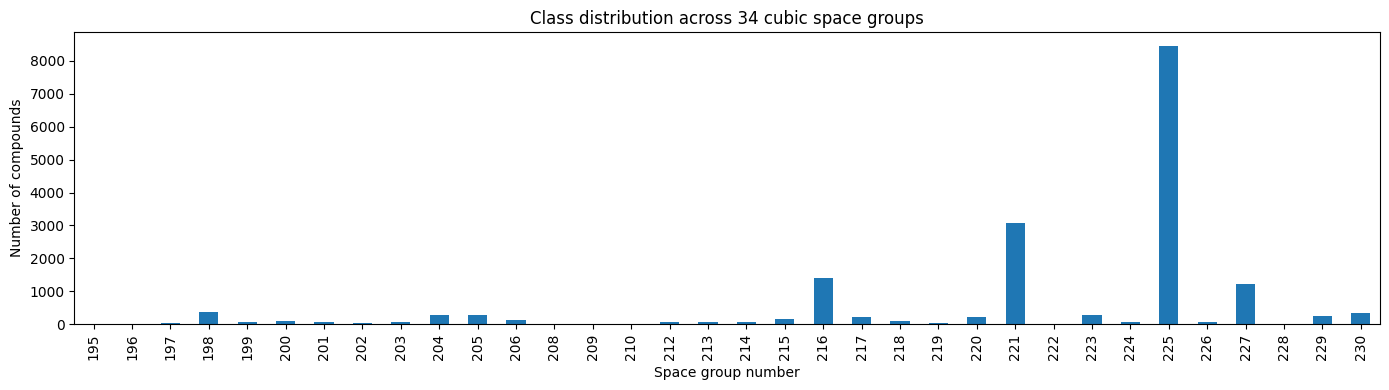

In [3]:
import matplotlib.pyplot as plt

counts = df['space_group'].value_counts().sort_index()
print(counts)

counts.plot(kind='bar', figsize=(14,4))
plt.xlabel('Space group number')
plt.ylabel('Number of compounds')
plt.title('Class distribution across 34 cubic space groups')
plt.tight_layout()
plt.show()

Cell 4 — Features and target

In [4]:
X = df.iloc[:, 5:].fillna(0).values
y = df.iloc[:, 1].values
print('Features:', X.shape, ' Classes:', len(set(y)))

Features: (17367, 256)  Classes: 34


Cell 5 — Split and train

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = RandomForestClassifier(
    criterion='entropy', n_estimators=100, max_features=80,
    max_depth=None, min_samples_leaf=1, min_samples_split=2,
    n_jobs=-1, random_state=42
)
clf.fit(X_train, y_train)

RandomForestClassifier(criterion='entropy', max_features=80, n_jobs=-1,
                       random_state=42)

Cell 6 — Evaluate on the held-out test set

In [6]:
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef

y_pred = clf.predict(X_test)
print('Accuracy   :', round(accuracy_score(y_test, y_pred), 3))
print('F1 weighted:', round(f1_score(y_test, y_pred, average='weighted'), 3))
print('MCC        :', round(matthews_corrcoef(y_test, y_pred), 3))

Accuracy   : 0.957
F1 weighted: 0.956
MCC        : 0.94


Cell 7 — Full 10-fold check (5–10 minutes)

In [7]:
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

scoring = {'accuracy': 'accuracy', 'f1_weighted': 'f1_weighted', 'MCC': make_scorer(matthews_corrcoef)}
scores = cross_validate(clf, X, y, scoring=scoring, cv=10, n_jobs=-1)

for metric in ['test_accuracy', 'test_f1_weighted', 'test_MCC']:
    print(metric, ':', round(np.mean(scores[metric]), 3), '+/-', round(np.std(scores[metric], ddof=1), 3))

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=10.
  warnings.warn(


test_accuracy : 0.949 +/- 0.03
test_f1_weighted : 0.947 +/- 0.028
test_MCC : 0.929 +/- 0.04


Cell 8 — Feature importance

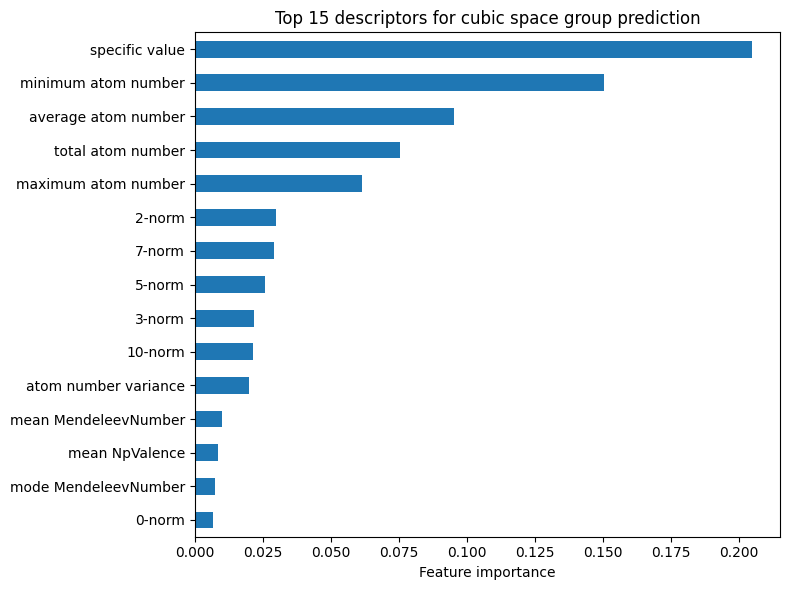

In [8]:
feature_names = df.columns[5:]
importances = clf.feature_importances_
top15 = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

top15.plot(kind='barh', figsize=(8,6))
plt.gca().invert_yaxis()
plt.xlabel('Feature importance')
plt.title('Top 15 descriptors for cubic space group prediction')
plt.tight_layout()
plt.show()

Cell 9 — Predict a brand-new formula

In [9]:
from matminer.featurizers.conversions import StrToComposition
from matminer.featurizers.composition import ElementProperty
from matminer.featurizers.base import MultipleFeaturizer
from matminer.featurizers import composition as cf

feature_calculators = MultipleFeaturizer([
    cf.ElementProperty.from_preset(preset_name='magpie'),
    cf.Stoichiometry(), cf.ValenceOrbital(props=['frac']), cf.IonProperty(fast=True),
    cf.BandCenter(), cf.ElementFraction(),
])
train_feature_names = list(df.columns[5:])

def featurize_new_formulas(formula_list):
    d = pd.DataFrame({'formula': formula_list})
    d = StrToComposition().featurize_dataframe(d, 'formula', ignore_errors=True)
    d = feature_calculators.featurize_dataframe(d, col_id='composition', ignore_errors=True)
    d['NComp'] = d['composition'].apply(len)
    d.columns = [c.replace('MagpieData ', '') for c in d.columns]
    d = d.reindex(columns=train_feature_names, fill_value=0)
    return d.fillna(0).values

new_formulas = ['MgAl2O4', 'SrTiO3', 'NaCl']
X_new = featurize_new_formulas(new_formulas)
predictions = clf.predict(X_new)
for f, sg in zip(new_formulas, predictions):
    print(f'{f}: predicted space group {sg}')

StrToComposition:   0%|          | 0/3 [00:00<?, ?it/s]

MultipleFeaturizer:   0%|          | 0/3 [00:00<?, ?it/s]

MgAl2O4: predicted space group 221
SrTiO3: predicted space group 221
NaCl: predicted space group 221


Cell 10 — Mount Google Drive (untested by me — this is the one step I can't verify myself)

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cell 11 — Find the file (searches instead of guessing the path)

In [11]:
import glob

matches = glob.glob('/content/drive/MyDrive/**/data.xlsx', recursive=True)
matches = [m for m in matches if not m.split('/')[-1].startswith('~$')]  # drop Excel lock files

print('Found:')
for m in matches:
    print(' -', m)

if len(matches) == 0:
    raise FileNotFoundError("No file named exactly 'data.xlsx' found in Drive. Check the filename.")
elif len(matches) > 1:
    print('WARNING: more than one data.xlsx found — pick the right one manually:')
    for i, m in enumerate(matches):
        print(f'  [{i}]', m)
    xlsx_path = matches[int(input('Enter the index of the correct file: '))]
else:
    xlsx_path = matches[0]
    print('Using:', xlsx_path)

Found:
 - /content/drive/MyDrive/data.xlsx
Using: /content/drive/MyDrive/data.xlsx


Cell 12 — Load it once, cache as CSV (this cell takes about 4–5 minutes — that's normal for a 136 MB Excel file, not a hang)

In [12]:
import pandas as pd, time

xlsx_path = matches[0]
print('Reading', xlsx_path, '... this takes several minutes, let it run.')
t0 = time.time()
df_all = pd.read_excel(xlsx_path)
print('Done in', round(time.time()-t0, 1), 'seconds. Shape:', df_all.shape)

df_all.to_csv('/content/data.csv', index=False)
print('Cached as /content/data.csv — every future cell reads this fast copy, not the slow xlsx again.')

is_multi_system = df_all['space_group'].max() > 194 and df_all['space_group'].min() < 195
print('Contains more than just cubic:', is_multi_system)

Reading /content/drive/MyDrive/data.xlsx ... this takes several minutes, let it run.
Done in 312.1 seconds. Shape: (102528, 261)
Cached as /content/data.csv — every future cell reads this fast copy, not the slow xlsx again.
Contains more than just cubic: True


Cell 13 — Crystal system per row

In [13]:
def crystal_system(sg):
    if 1 <= sg <= 2: return 'triclinic'
    if 3 <= sg <= 15: return 'monoclinic'
    if 16 <= sg <= 74: return 'orthorhombic'
    if 75 <= sg <= 142: return 'tetragonal'
    if 143 <= sg <= 167: return 'trigonal'
    if 168 <= sg <= 194: return 'hexagonal'
    if 195 <= sg <= 230: return 'cubic'
    return 'unknown'

df_all['crystal_system'] = df_all['space_group'].apply(crystal_system)
print(df_all['crystal_system'].value_counts())

crystal_system
monoclinic      23024
orthorhombic    22392
cubic           17367
tetragonal      12675
triclinic        9440
trigonal         9429
hexagonal        8201
Name: count, dtype: int64


Cell 14 — Train one model per crystal system

cubic : 0.957
hexagonal : 0.898
monoclinic : 0.691
orthorhombic : 0.752
tetragonal : 0.847
triclinic : 0.822
trigonal : 0.807


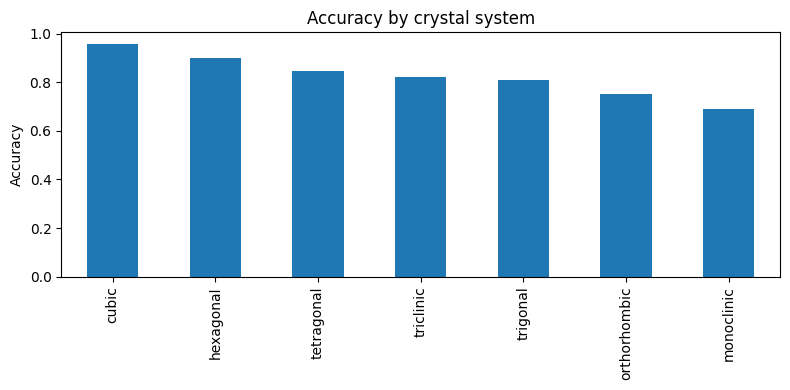

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

results = {}
for system_name, group in df_all.groupby('crystal_system'):
    counts = group['space_group'].value_counts()
    group = group[group['space_group'].isin(counts[counts >= 2].index)]
    Xs = group.iloc[:, 5:261].fillna(0).values
    ys = group['space_group'].values
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.2, random_state=42, stratify=ys)
    m = RandomForestClassifier(criterion='entropy', n_estimators=100, max_features=80, n_jobs=-1, random_state=42)
    m.fit(Xtr, ytr)
    acc = accuracy_score(yte, m.predict(Xte))
    results[system_name] = round(acc, 3)
    print(system_name, ':', round(acc, 3))

pd.Series(results).sort_values(ascending=False).plot(kind='bar', figsize=(8,4))
plt.ylabel('Accuracy'); plt.title('Accuracy by crystal system'); plt.tight_layout(); plt.show()

Cell 15 — Reload the cubic baseline (run before 16–18)

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv('SG_predict/ML/cubic.csv')
X = df.iloc[:, 5:].fillna(0).values
y = df.iloc[:, 1].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
clf = RandomForestClassifier(criterion='entropy', n_estimators=100, max_features=80,
                              max_depth=None, min_samples_leaf=1, min_samples_split=2,
                              n_jobs=-1, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print('Baseline ready:', round(accuracy_score(y_test, y_pred), 3))

Baseline ready: 0.957


Cell 16 — XGBoost comparison

In [16]:
!pip install xgboost --quiet

In [17]:
import numpy as np, xgboost as xgb
from sklearn.metrics import accuracy_score

label_to_index = {v: i for i, v in enumerate(sorted(set(y)))}
y_train_enc = np.array([label_to_index[v] for v in y_train])
y_test_enc = np.array([label_to_index[v] for v in y_test])

xgb_clf = xgb.XGBClassifier(n_estimators=100, max_depth=6, n_jobs=-1, random_state=42, eval_metric='mlogloss')
xgb_clf.fit(X_train, y_train_enc)
xgb_pred = xgb_clf.predict(X_test)
print('Random Forest accuracy:', round(accuracy_score(y_test, y_pred), 3))
print('XGBoost accuracy      :', round(accuracy_score(y_test_enc, xgb_pred), 3))

Random Forest accuracy: 0.957
XGBoost accuracy      : 0.954


Cell 17 — Hyperparameter search

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {'n_estimators': [50, 100, 200], 'max_features': [40, 80, 120]}
search = GridSearchCV(RandomForestClassifier(criterion='entropy', n_jobs=-1, random_state=42),
                       param_grid, cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
print('Best settings found:', search.best_params_)
print('Best cross-validated accuracy:', round(search.best_score_, 3))

Fitting 3 folds for each of 9 candidates, totalling 27 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Best settings found: {'max_features': 80, 'n_estimators': 100}
Best cross-validated accuracy: 0.953


Cell 18 — Confusion matrix

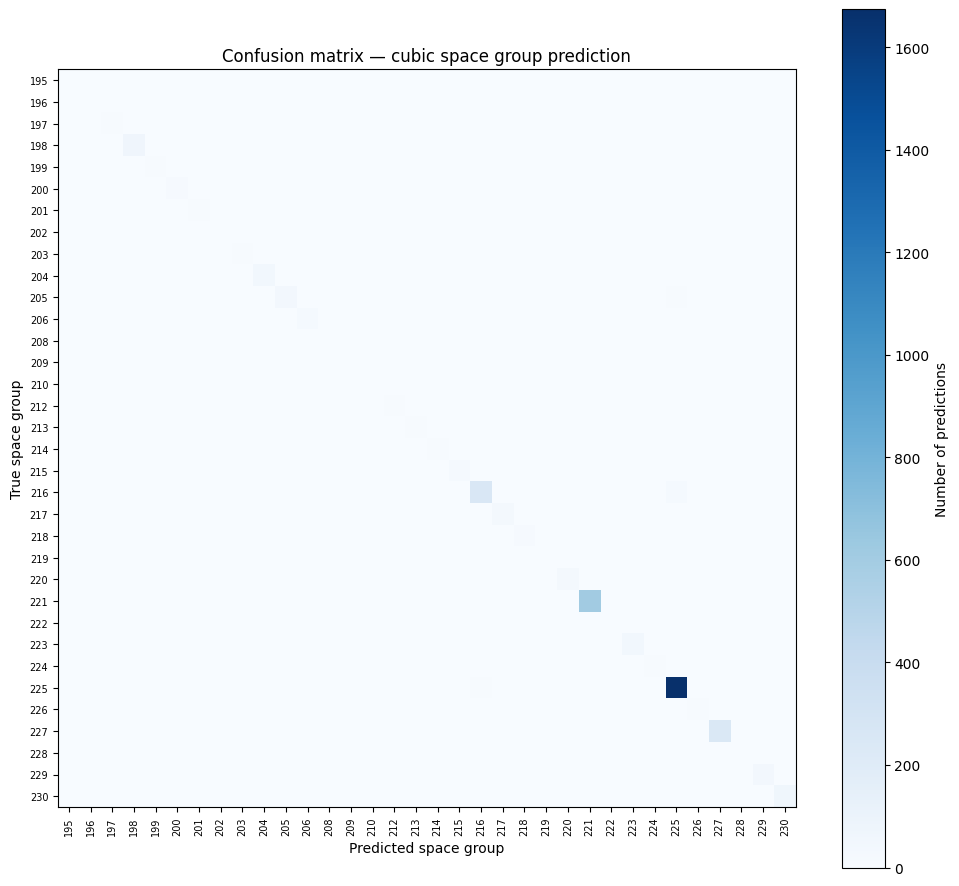

In [19]:
from sklearn.metrics import confusion_matrix

labels_sorted = sorted(set(y))
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

plt.figure(figsize=(10,9))
plt.imshow(cm, cmap='Blues')
plt.colorbar(label='Number of predictions')
plt.xticks(range(len(labels_sorted)), labels_sorted, rotation=90, fontsize=7)
plt.yticks(range(len(labels_sorted)), labels_sorted, fontsize=7)
plt.xlabel('Predicted space group'); plt.ylabel('True space group')
plt.title('Confusion matrix — cubic space group prediction')
plt.tight_layout(); plt.show()